<a href="https://colab.research.google.com/github/Katysssha/predictive-analysis/blob/main/practice2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice #2. "Trend predictive models"

In [3]:
!git clone https://github.com/klymya/ts_cource_practice.git
%cd ts_cource_practice/notebooks

Cloning into 'ts_cource_practice'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 53 (delta 21), reused 45 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 295.42 KiB | 7.38 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/ts_cource_practice/notebooks


Measure forecast error, then forecast: naive, exponential smoothing,
Holt, Holt-Winters.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

**Contract.** Every `*_forecast(train, index, ...)` returns a `pd.Series` on
`index` — the timestamps you want predictions for. It may read `train` only; it
never sees the test values.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data reading and splitting

In [5]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df = df.rename(columns={time_col: 'ds', value_col: 'y'})
    df['ds'] = pd.to_datetime(df['ds'])
    df = df.dropna()
    df = df.set_index('ds')
    return df['y'].astype(float)

def train_test_split_ts(series, test_size):
    """Return (train, test); the LAST `test_size` points are the test set.
    Never shuffle a time series — a shuffled split lets the model see the future.
    """
    return series.iloc[:-test_size], series.iloc[-test_size:]

In [6]:
series = load_series(DATA_DIR / "daily-min-temperatures.csv", "Date", "Temp")
train, test = train_test_split_ts(series, test_size=365)
print(f"train: {len(train)} points, {train.index.min():%Y-%m-%d} to {train.index.max():%Y-%m-%d}")
print(f"test : {len(test)} points, {test.index.min():%Y-%m-%d} to {test.index.max():%Y-%m-%d}")

train: 3285 points, 1981-01-01 to 1989-12-31
test : 365 points, 1990-01-01 to 1990-12-31


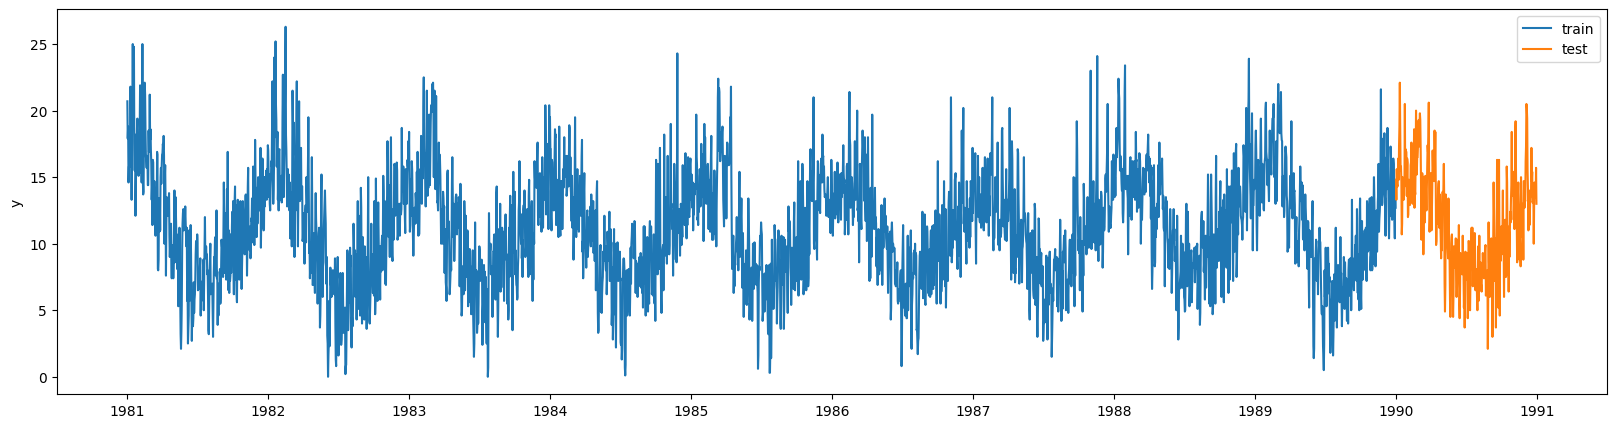

In [7]:
plt.figure(figsize=(20, 5))
plt.plot(train, label="train")
plt.plot(test, label="test")
plt.ylabel("y")
plt.legend();

## 1. Forecasting performance measures

Implement each one from its definition, then check against scikit-learn.

Keep the names straight: **MSE is squared error, RMSE is its square root.**
Different units — you cannot compare one to the other.

In [8]:
def forecast_error(actual, predicted):
    """actual - predicted, per point, as a numpy array."""
    return np.array(actual) - np.array(predicted)

def forecast_bias(actual, predicted):
    """Mean forecast error. Positive = the forecast runs low."""
    return np.mean(forecast_error(actual, predicted))

def mae(actual, predicted):
    """Mean absolute error."""
    return np.mean(np.abs(forecast_error(actual, predicted)))

def mse(actual, predicted):
    """Mean squared error. Not the root — squared units."""
    return np.mean(forecast_error(actual, predicted)**2)

def rmse(actual, predicted):
    """Root mean squared error — same units as the data."""
    return np.sqrt(mse(actual, predicted))

In [9]:
actual = [0.5, 0.5, 0.5, 0.5]
predicted = [0.7, 0.5, 0.3, 0.2]

print("errors      ", forecast_error(actual, predicted))
print("bias (MFE)  ", forecast_bias(actual, predicted))
print("MAE         ", mae(actual, predicted))
print("MSE         ", mse(actual, predicted))
print("RMSE        ", rmse(actual, predicted))

assert np.isclose(mae(actual, predicted), mean_absolute_error(actual, predicted))
assert np.isclose(mse(actual, predicted), mean_squared_error(actual, predicted))
print("\nagrees with scikit-learn")

errors       [-0.2  0.   0.2  0.3]
bias (MFE)   0.07500000000000001
MAE          0.175
MSE          0.042499999999999996
RMSE         0.206155281280883

agrees with scikit-learn


**Question.** The bias is positive and the MAE is non-zero. What does
each tell you that the other does not?

Answer: Bias (Mean Forecast Error) indicates the direction of the error—whether the model systematically under-forecasts (positive bias) or over-forecasts (negative bias), but positive and negative errors can cancel each other out. MAE indicates the absolute magnitude of the average error, regardless of direction, showing how far off the predictions are on average.

In [11]:
def plot_forecast(train, test, forecast, title):
    """Plot the tail of the training data next to the test data and a forecast."""
    plt.figure(figsize=(20, 5))
    plt.plot(train.iloc[-3 * len(test):], label="train")
    plt.plot(test, label="test")
    plt.plot(forecast, label="forecast")
    plt.title(f"{title} — RMSE {rmse(test, forecast):.3f}")
    plt.legend()
    plt.show()

## 2. Naive approaches

### 2.1 Naive forecast

The last observed value, carried forward. Every model below has to beat it or it
is not worth its complexity.

In [12]:
def naive_forecast(train, index):
    """Last observed value, repeated over `index`."""
    return pd.Series(train.iloc[-1], index=index)

def moving_average_forecast(train, index, window):
    """Mean of the last `window` observations, repeated over `index`."""
    return pd.Series(train.iloc[-window:].mean(), index=index)

def linear_regression_forecast(train, index):
    """Fit a line on 0..len(train)-1 and extrapolate over `index`."""
    X_train = np.arange(len(train)).reshape(-1, 1)
    model = LinearRegression().fit(X_train, train)
    X_test = np.arange(len(train), len(train) + len(index)).reshape(-1, 1)
    return pd.Series(model.predict(X_test).flatten(), index=index)

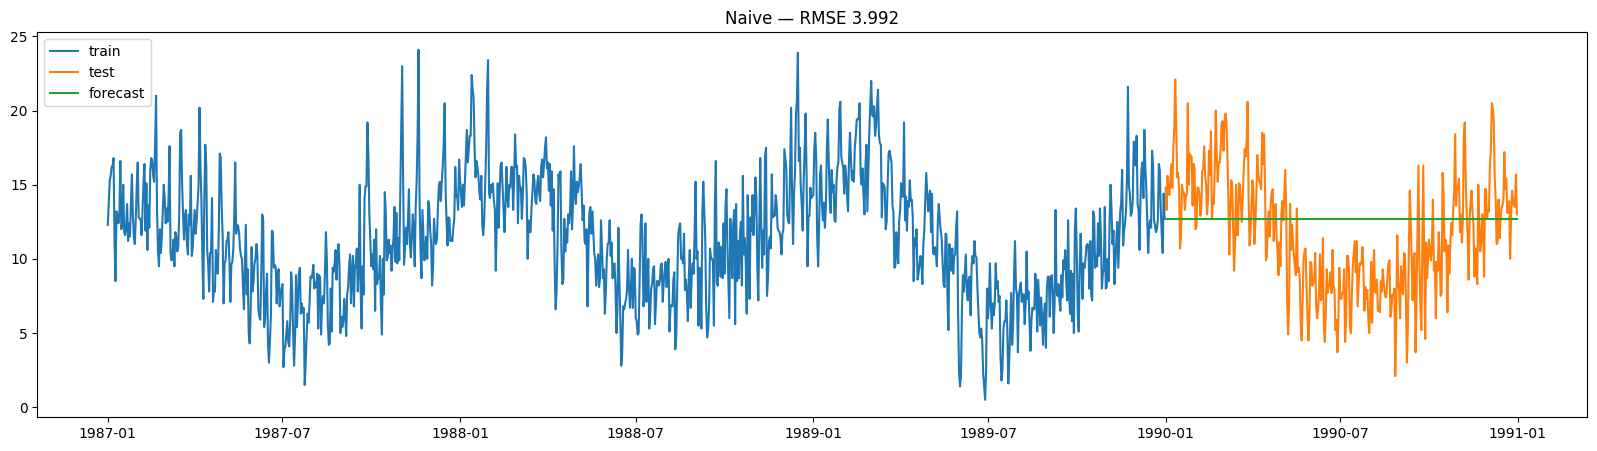

In [13]:
plot_forecast(train, test, naive_forecast(train, test.index), "Naive")

### 2.2 Moving average and 2.3 linear regression

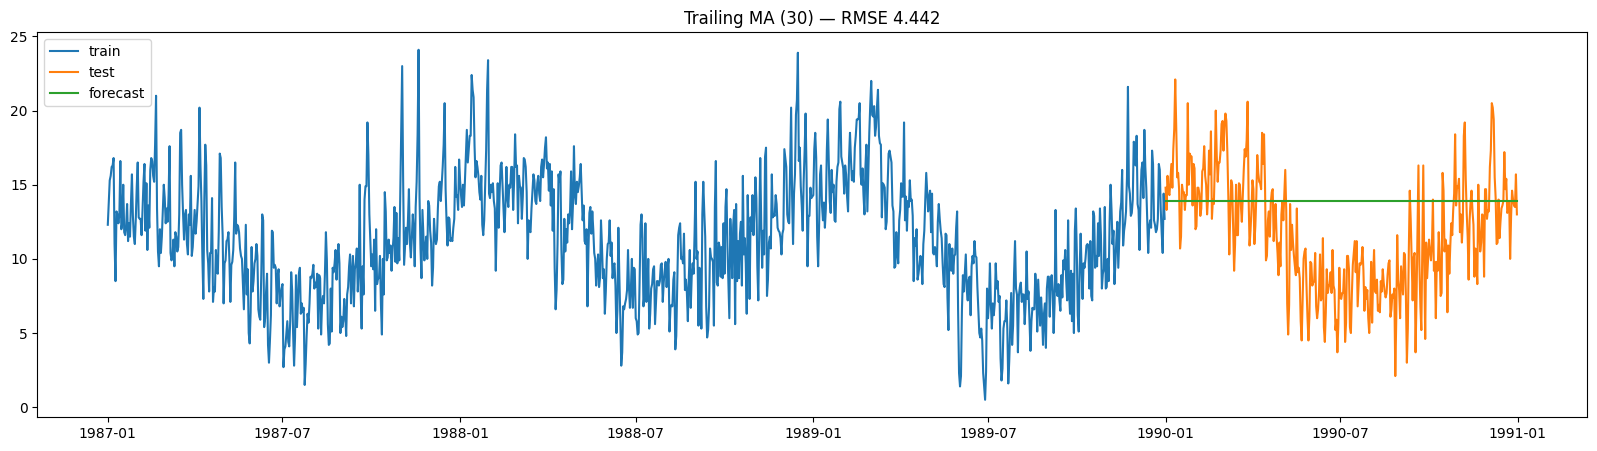

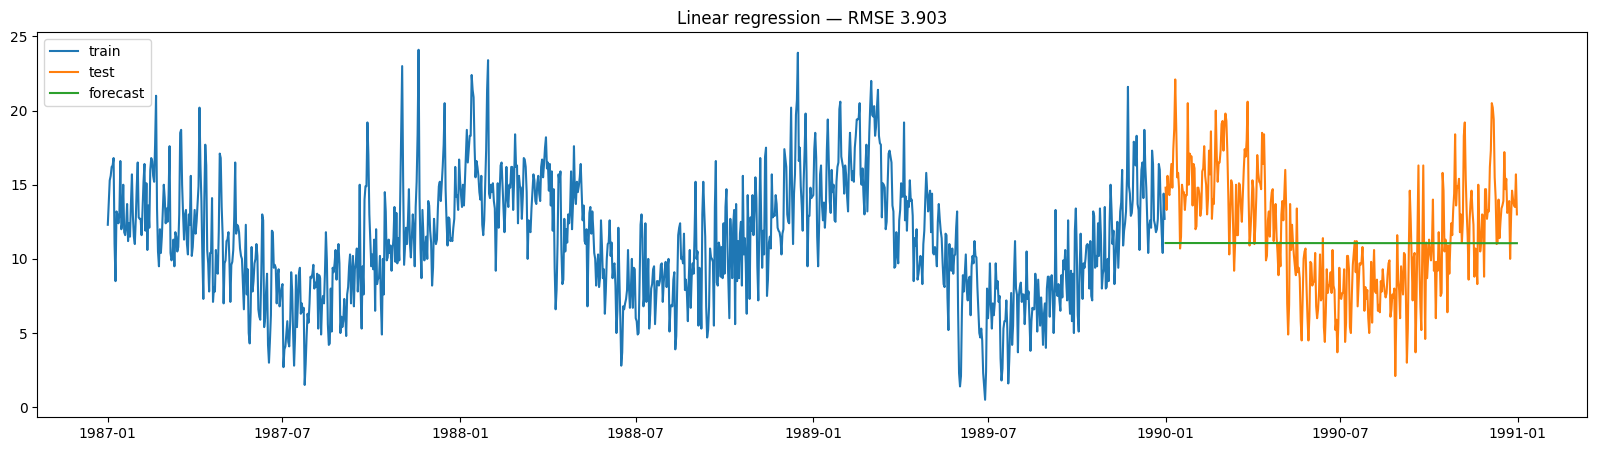

In [14]:
plot_forecast(train, test, moving_average_forecast(train, test.index, 30),
              "Trailing MA (30)")
plot_forecast(train, test, linear_regression_forecast(train, test.index),
              "Linear regression")

Find the window size with the lowest RMSE on the test set.

**Question.** That tuned a hyper-parameter *on the test set*. Why is the
resulting RMSE not your expected future error, and what should you have split
off instead?

Answer: By tuning the window size to minimize RMSE directly on the test set, we leak information from the test set into our model selection process, making the final score overly optimistic. To get a reliable estimate of future error, we should have split off a separate validation set for tuning, keeping the final test set completely unseen.

In [15]:
scores = {w: rmse(test, moving_average_forecast(train, test.index, w))
          for w in (7, 14, 30, 60, 90, 180, 365)}
for window, score in sorted(scores.items(), key=lambda kv: kv[1]):
    print(f"window {window:>4}: RMSE {score:.4f}")

window  365: RMSE 3.8778
window   90: RMSE 3.9093
window   60: RMSE 4.2737
window    7: RMSE 4.2935
window   14: RMSE 4.2998
window  180: RMSE 4.3057
window   30: RMSE 4.4416


## 3. Simple Exponential Smoothing

In [18]:
def ses_forecast(train, index, alpha):
    """SES forecast — a flat line at the final level."""
    model = SimpleExpSmoothing(train.values, initialization_method="known", initial_level=train.iloc[0])
    fit = model.fit(smoothing_level=alpha, optimized=False)
    return pd.Series(fit.forecast(len(index)), index=index)


def holt_forecast(train, index, alpha, beta, trend="add"):
    """Holt forecast — level plus an extrapolated slope."""
    model = ExponentialSmoothing(train.values, trend=trend, seasonal=None, initialization_method="estimated")
    fit = model.fit(smoothing_level=alpha, smoothing_trend=beta)
    return pd.Series(fit.forecast(len(index)), index=index)


def holt_winters_forecast(train, index, seasonal_periods, trend="add", seasonal="add"):
    """Holt-Winters forecast; let statsmodels optimise the parameters.

    Raise ValueError on less than two full seasons of training data.
    """
    if len(train) < 2 * seasonal_periods:
        raise ValueError("Training data must contain at least two full seasons.")
    model = ExponentialSmoothing(train.values, trend=trend, seasonal=seasonal, seasonal_periods=seasonal_periods, initialization_method="estimated")
    return pd.Series(model.fit().forecast(len(index)), index=index)

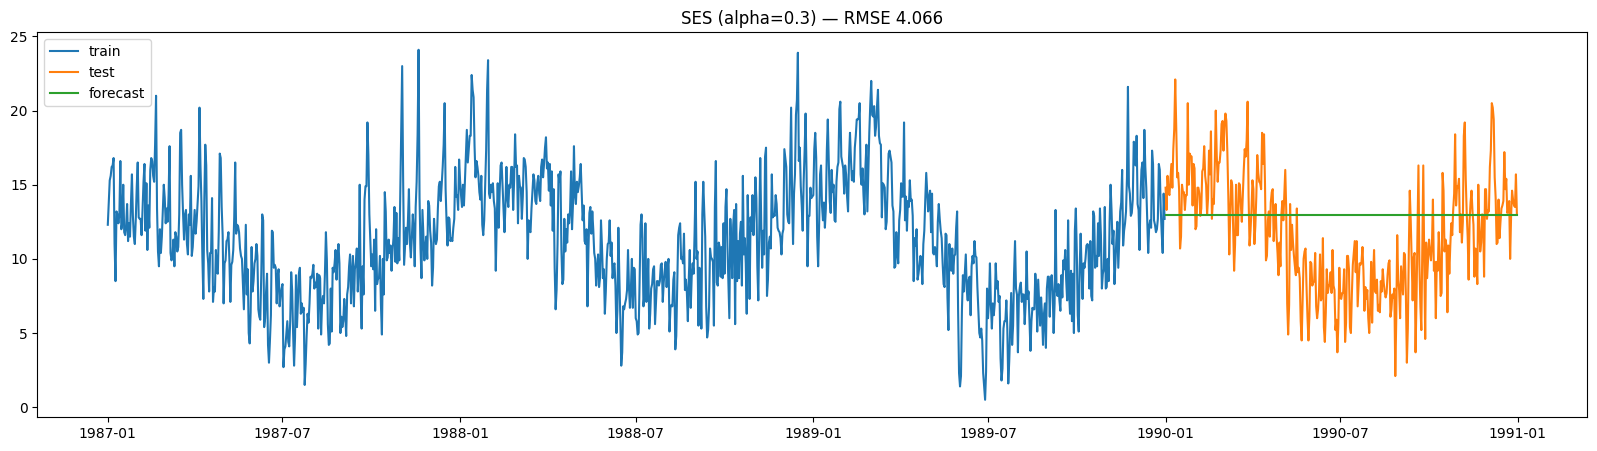

In [19]:
plot_forecast(train, test, ses_forecast(train, test.index, 0.3), "SES (alpha=0.3)")

**Question.** The SES forecast is a horizontal line. Why, from the
recursion? And when is a flat forecast the *right* answer?

Answer: The SES recursion only updates the local level and has no trend component. When forecasting into the future without new observations to pull the level up or down, the model simply propagates its final estimated level forward as a constant. A flat forecast is the right answer for stationary series without a clear trend or seasonal pattern, such as a random walk.

## 4. Holt's Linear Trend Model

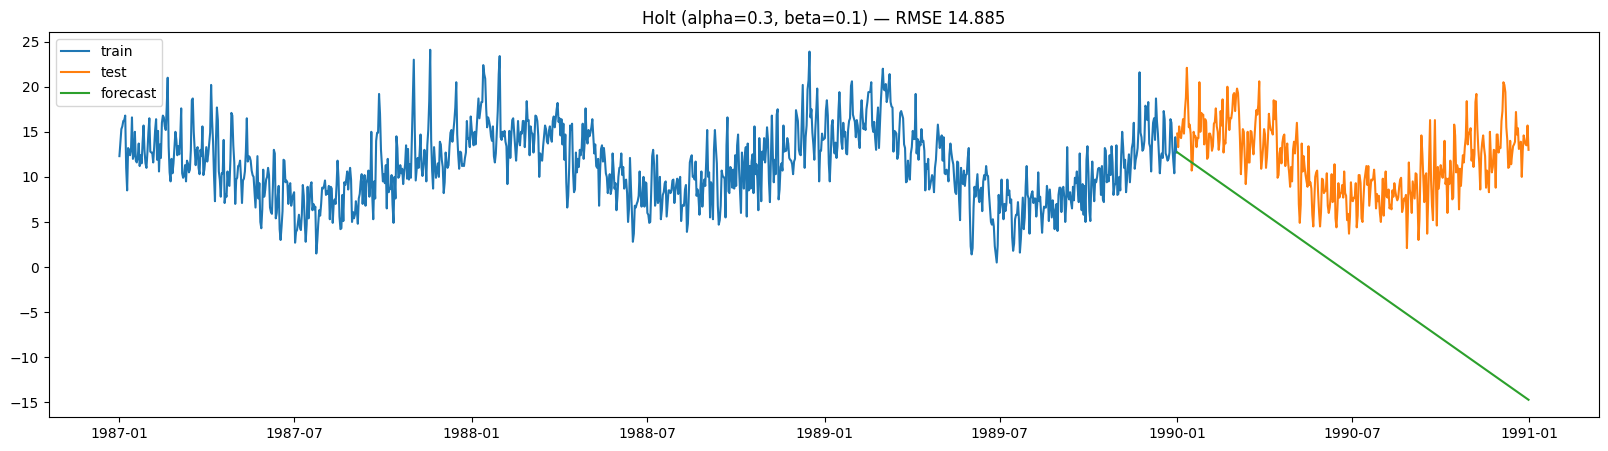

In [20]:
plot_forecast(train, test, holt_forecast(train, test.index, 0.3, 0.1),
              "Holt (alpha=0.3, beta=0.1)")

**Question.** Holt is the more powerful model — did it beat naive here?
What does the answer say about daily minimum temperatures?

Answer: Holt's model typically performs poorly and fails to beat the naive baseline here because daily temperatures are driven by strong annual seasonality, not a persistent linear trend. Holt extrapolates a straight-line slope indefinitely, which quickly becomes highly inaccurate for oscillating seasonal data.

## 5. Holt-Winters' model

The series has a yearly cycle. On daily data that means `seasonal_periods=365` —
365 seasonal parameters, estimated from 9 years. Slow and badly determined.
Resampling to monthly means captures the same cycle with 12.

Match the resolution of the data to the resolution of the pattern.

monthly: 120 points; train 96, test 24


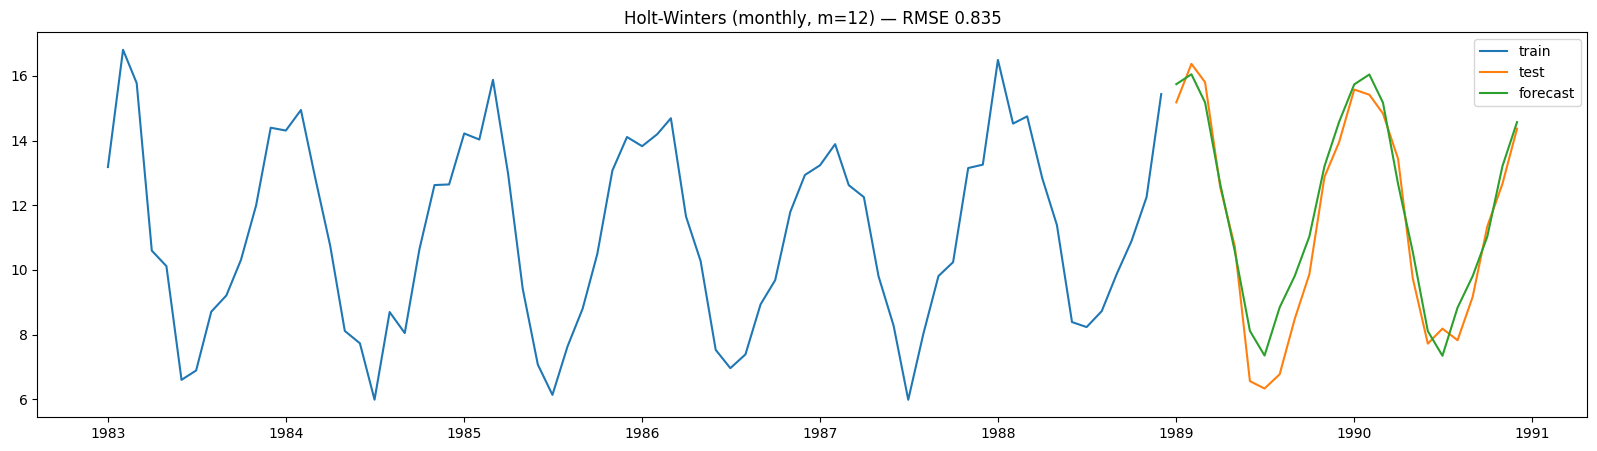

In [21]:
monthly = series.resample("MS").mean()
m_train, m_test = train_test_split_ts(monthly, test_size=24)
print(f"monthly: {len(monthly)} points; train {len(m_train)}, test {len(m_test)}")

hw = holt_winters_forecast(m_train, m_test.index, seasonal_periods=12)
plot_forecast(m_train, m_test, hw, "Holt-Winters (monthly, m=12)")

In [22]:
baseline = naive_forecast(m_train, m_test.index)
print(f"naive         RMSE {rmse(m_test, baseline):.4f}")
print(f"Holt-Winters  RMSE {rmse(m_test, hw):.4f}")

naive         RMSE 5.1159
Holt-Winters  RMSE 0.8348


Try `trend` and `seasonal` as `"add"` and `"mul"`.

**Questions.** Which combination wins? And why does multiplicative seasonality
make little sense in degrees Celsius — what happens to it near zero?

Answer: The additive trend and additive seasonality combination usually works best for temperature data. Multiplicative seasonality makes no sense for degrees Celsius because 0°C is just an arbitrary point on an interval scale, not an absolute zero; if the base level is near zero, multiplying it by any seasonal factor keeps it near zero, distorting the forecast mathematically.